Chuẩn bị thư viện và đọc dữ liệu
- *Trước* tiên, tải file dữ liệu CSV lên Google Colab, sau đó chạy:

In [14]:
print("Nguyen Duy Binh - 6451071005")
import pandas as pd
import matplotlib.pyplot as plt

# Đọc dữ liệu CSV
df = pd.read_excel('tb_tracking.xlsx')

# Xem 5 dòng đầu tiên
print(df.head())

# Xem số dòng và số cột
print(df.shape)

Nguyen Duy Binh - 6451071005
     1    1.1    2    3      4 2016-12-20 12:52:29
0  2.0    1.0  2.0  3.0    4.0 2016-12-20 12:52:31
1  3.0  100.0  2.0  3.0    4.0 2016-12-20 12:52:35
2  4.0  100.0  2.0  3.0  400.0 2016-12-20 12:52:37
3  5.0    1.0  2.0  3.0    4.0 2016-12-20 13:02:01
4  6.0  100.0  2.0  3.0  400.0 2016-12-20 13:02:24
(33339, 6)


In [10]:
df.columns = [
    'id',
    'device_id',
    'co_level',
    'humidity',
    'temperature',
    'time'
]

print(df.head())
print(df.columns)

    id  device_id  co_level  humidity  temperature                time
0  2.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:31
1  3.0      100.0       2.0       3.0          4.0 2016-12-20 12:52:35
2  4.0      100.0       2.0       3.0        400.0 2016-12-20 12:52:37
3  5.0        1.0       2.0       3.0          4.0 2016-12-20 13:02:01
4  6.0      100.0       2.0       3.0        400.0 2016-12-20 13:02:24
Index(['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time'], dtype='object')


b) Do điều chỉnh cảm biến nên dữ liệu đo được bắt đầu từ ngày 03/01/2018 mới chính
xác. Những dữ liệu còn lại không có giá trị, yêu cầu sinh viên loại bỏ.

In [11]:
# Chuyển cột time sang kiểu ngày giờ
df['time'] = pd.to_datetime(
    df['time'],
    dayfirst=True,
    errors='coerce'
)

# Loại bỏ các dòng có thời gian không hợp lệ
df = df.dropna(subset=['time'])

# Chỉ giữ dữ liệu từ ngày 03/01/2018 trở đi
df = df[df['time'] >= '2018-01-03'].copy()

print("Số dòng sau khi lọc:", len(df))
print(df.head())

Số dòng sau khi lọc: 1918
            id  device_id  co_level  humidity  temperature                time
31418  31420.0        1.0       2.0       3.0          4.0 2018-01-03 13:11:07
31419  31421.0        1.0       2.0       3.0          4.0 2018-01-03 13:15:10
31420  31422.0    99005.0      58.0      26.0          0.0 2018-01-03 13:17:30
31421  31423.0    99005.0      58.0      26.0          0.0 2018-01-03 13:19:21
31422  31424.0    99005.0      58.0      26.0          0.0 2018-01-03 13:24:17


Giải thích:
- pd.to_datetime() chuyển dữ liệu thời gian thành kiểu ngày giờ.
- errors='coerce' chuyển thời gian sai định dạng thành NaT.
- dropna() loại bỏ những dòng không có thời gian hợp lệ.
- Điều kiện lọc loại bỏ các dữ liệu trước ngày 03/01/2018.

c) Từ cột time sinh viên bóc tách dữ liệu thành thời điểm đo đạc trong ngày tính theo
phút, đặt tên là minutes.

In [12]:
df['minutes'] = (
    df['time'].dt.hour * 60
    + df['time'].dt.minute
    + df['time'].dt.second / 60
)

print(df[['time', 'minutes']].head())

                     time     minutes
31418 2018-01-03 13:11:07  791.116667
31419 2018-01-03 13:15:10  795.166667
31420 2018-01-03 13:17:30  797.500000
31421 2018-01-03 13:19:21  799.350000
31422 2018-01-03 13:24:17  804.283333


d) Vẽ đồ thị phân tán (scatter-plots) lần lượt biểu diễn dữ liệu nồng độ khí CO, độ ẩm
và nhiệt độ theo cột minutes vừa tạo ở yêu cầu trên.

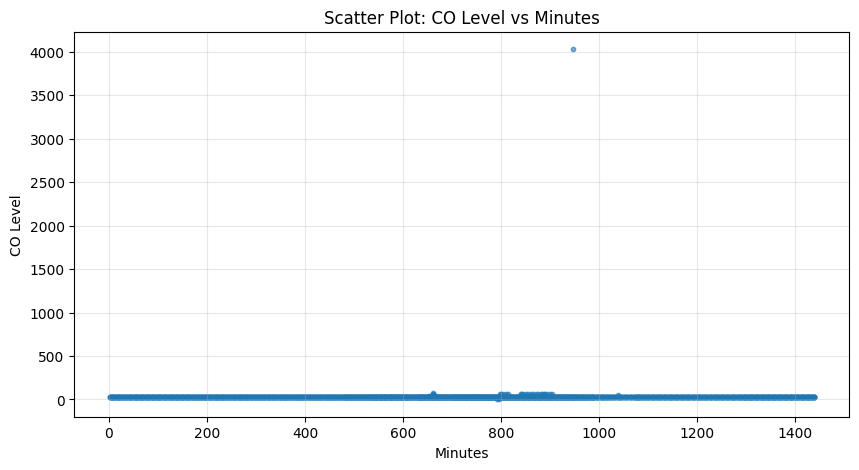

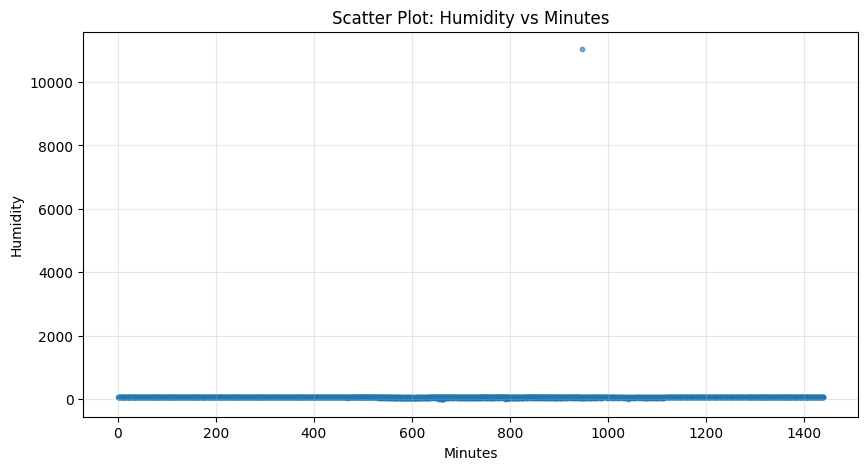

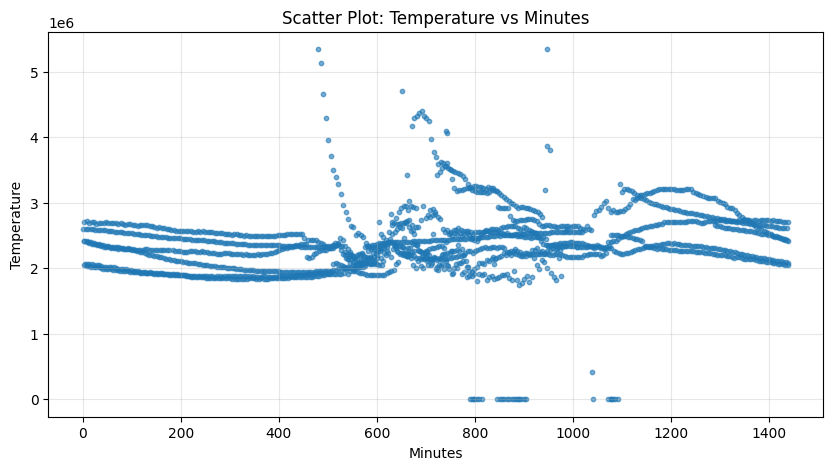

In [13]:
# Chuyển các cột đo lường thành kiểu số
cols = ['co_level', 'humidity', 'temperature']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Loại bỏ các dòng thiếu dữ liệu đo lường
df = df.dropna(subset=cols + ['minutes'])

# Biểu đồ 1: Nồng độ CO theo phút
plt.figure(figsize=(10, 5))
plt.scatter(df['minutes'], df['co_level'], s=10, alpha=0.6)
plt.xlabel('Minutes')
plt.ylabel('CO Level')
plt.title('Scatter Plot: CO Level vs Minutes')
plt.grid(True, alpha=0.3)
plt.show()

# Biểu đồ 2: Độ ẩm theo phút
plt.figure(figsize=(10, 5))
plt.scatter(df['minutes'], df['humidity'], s=10, alpha=0.6)
plt.xlabel('Minutes')
plt.ylabel('Humidity')
plt.title('Scatter Plot: Humidity vs Minutes')
plt.grid(True, alpha=0.3)
plt.show()

# Biểu đồ 3: Nhiệt độ theo phút
plt.figure(figsize=(10, 5))
plt.scatter(df['minutes'], df['temperature'], s=10, alpha=0.6)
plt.xlabel('Minutes')
plt.ylabel('Temperature')
plt.title('Scatter Plot: Temperature vs Minutes')
plt.grid(True, alpha=0.3)
plt.show()